In [327]:
import pandas as pd

In [700]:
dms_candidates_inference_kinbertv1 = pd.read_csv("../../data/virus_dms/230105_dms_candidates_inference_kinbertv1.csv").iloc[:,1:]
dms_candidates_inference_kinbertv2 = pd.read_csv("../../data/virus_dms/230105_dms_candidates_inference_kinbertv2.csv").iloc[:,1:]

In [701]:
dms_candidates_inference_kinbertv2.head(1)

,substrate,p_ind,wt_aa,pred_kinase,pred_kinase_prob
0,WSN,15,T,"['CK2a1', 'CK2a2', 'SRC', 'SNRK', 'MELK', 'Slo...","['CK2a1:2.04:0.98', 'CK2a2:1.10:0.89', 'SRC:1...."


In [329]:
pkidb = pd.read_csv("./pkidb_2025-04-15.tsv",sep = '\t', encoding='latin-1')
pkidb_wtarget = pkidb.loc[(~pkidb["Name"].isna())&(~pkidb["Targets"].isna()),["Name","Phase","Targets","Kinase families",'FDA_approved']]

In [330]:

# assume df is your original dataframe
pkidb_wtarget = (
    pkidb_wtarget
    .assign(
        Targets=pkidb_wtarget["Targets"]
        .str.replace(r"<.*?>", "", regex=True)  # remove HTML like <br>(*)
        .str.split(r"\s*;\s*")                  # split on ';'
    )
    .explode("Targets")
    .rename(columns={"Targets": "Targets"})
    .reset_index(drop=True)
)

pkidb_wtarget

,Name,Phase,Targets,Kinase families,FDA_approved
0,Abemaciclib,4.0,CDK4,CMGC,Y
1,Abemaciclib,4.0,CDK6,CMGC,Y
2,Acalabrutinib,4.0,BTK,Tyr,Y
3,Acalisib,2.0,PIK3CA,Atypical,NaN
4,Acumapimod,2.0,MAPK14,CMGC,NaN
...,...,...,...,...,...
493,Vistusertib,2.0,MTOR,Atypical,NaN
494,Volasertib,3.0,PLK1,Other,NaN
495,Voruciclib,2.0,CDK4,CMGC,NaN
496,Voxtalisib,2.0,PIK3CA,Atypical,NaN


In [331]:
drugbank_uniprot_links = pd.read_csv("../../data/kinase_inhibitor_dbs/drugbank_uniprot_links.csv", engine='python')
drugbank_uniprot_links = drugbank_uniprot_links

In [332]:
human_kinome = pd.read_csv("../../data/human_kinome.csv")

In [333]:
drugbank_uniprot_links_kinase = pd.merge(drugbank_uniprot_links,human_kinome,left_on = "UniProt ID",right_on="UniprotID")

In [334]:
pkidb_wtarget_kinase = pd.concat([pd.merge(pkidb_wtarget,human_kinome,left_on = "Targets",right_on="gene"),
           pd.merge(pkidb_wtarget,human_kinome,left_on = "Targets",right_on="alias"),
           pd.merge(pkidb_wtarget,human_kinome,left_on = "Targets",right_on="HGNC")]).drop_duplicates().sort_values("Name")

In [335]:
pkidb_wtarget_kinase

,Name,Phase,Targets,Kinase families,FDA_approved,gene,alias,HGNC,Kinase Name,Group,Family,SubFamily,UniprotID
0,Abemaciclib,4.0,CDK4,CMGC,Y,CDK4,CDK4,CDK4,Cyclin-dependent kinase 4,CMGC,CDK,CDK4,P11802
1,Abemaciclib,4.0,CDK6,CMGC,Y,CDK6,CDK6,CDK6,Cyclin-dependent kinase 6,CMGC,CDK,CDK4,Q00534
2,Acalabrutinib,4.0,BTK,Tyr,Y,BTK,BTK,BTK,Tyrosine-protein kinase BTK,TK,Tec,NaN,Q06187
3,Acumapimod,2.0,MAPK14,CMGC,NaN,p38a,p38a,MAPK14,Mitogen-activated protein kinase 14,CMGC,MAPK,p38,Q16539
4,Acumapimod,2.0,MAPK11,CMGC,NaN,p38b,p38b,MAPK11,Mitogen-activated protein kinase 11,CMGC,MAPK,p38,Q15759
...,...,...,...,...,...,...,...,...,...,...,...,...,...
315,Vemurafenib,4.0,BRAF,TKL,Y,BRAF,BRAF,BRAF,Serine/threonine-protein kinase B-raf,TKL,RAF,NaN,P15056
481,Vistusertib,2.0,MTOR,Atypical,NaN,FRAP,FRAP,MTOR,Serine/threonine-protein kinase mTOR,Atypical,PIKK,FRAP,P42345
316,Volasertib,3.0,PLK1,Other,NaN,PLK1,PLK1,PLK1,Serine/threonine-protein kinase PLK1,Other,PLK,NaN,P53350
317,Voruciclib,2.0,CDK4,CMGC,NaN,CDK4,CDK4,CDK4,Cyclin-dependent kinase 4,CMGC,CDK,CDK4,P11802


In [336]:
drugbank_uniprot_links_kinase_min = drugbank_uniprot_links_kinase.loc[:,["Name","UniProt ID","gene"]]
drugbank_uniprot_links_kinase_min.columns = ["drug_name","kinase_acc","kinase_name"]

In [337]:
pkidb_wtarget_kinase_min = pkidb_wtarget_kinase.loc[:,["Name","UniprotID","gene"]]
pkidb_wtarget_kinase_min.columns = ["drug_name","kinase_acc","kinase_name"]

In [338]:
pkidb_wtarget.loc[~pkidb_wtarget['Targets'].isin(pkidb_wtarget_kinase['Targets']),'Targets'].drop_duplicates()

3      PIK3CA
79     PIK3CB
93     PIK3CG
94     PIK3CD
121     VEGFA
138     NR1I2
444     PDGFD
Name: Targets, dtype: object

In [455]:
drugbank_uniprot_links_kinase_min.tail(50)

,drug_name,kinase_acc,kinase_name
1587,Upadacitinib,P23458,JAK1
1588,Upadacitinib,P23458,JAK1_b
1589,Pemigatinib,P11362,FGFR1
1590,Pemigatinib,P21802,FGFR2
1591,Pemigatinib,P22607,FGFR3
1592,Pemigatinib,P22455,FGFR4
1593,Tepotinib,P08581,MET
1594,Avapritinib,P10721,KIT
1595,Abivertinib,P00533,EGFR
1596,Abivertinib,Q06187,BTK


In [518]:
additional_drug = pd.DataFrame([{'BAY 1816032','O43683','BUB1'}])
additional_drug.columns = ['drug_name','kinase_acc','kinase_name']

In [519]:
drug_kinase_uniprot = pd.concat([pkidb_wtarget_kinase_min,drugbank_uniprot_links_kinase_min,additional_drug]).drop_duplicates()
# drug_kinase_uniprot = pd.concat([pkidb_wtarget_kinase_min]).drop_duplicates()

In [520]:
drug_kinase_uniprot = drug_kinase_uniprot.loc[drug_kinase_uniprot['drug_name']!='ATP',:]

In [521]:
drug_kinase_uniprot

,drug_name,kinase_acc,kinase_name
0,Abemaciclib,P11802,CDK4
1,Abemaciclib,Q00534,CDK6
2,Acalabrutinib,Q06187,BTK
3,Acumapimod,Q16539,p38a
4,Acumapimod,Q15759,p38b
...,...,...,...
1633,Amivantamab,P00533,EGFR
1634,Amivantamab,P08581,MET
1635,Belumosudil,O75116,ROCK2
1636,Belumosudil,Q13464,ROCK1


In [522]:
drug_kinase_uniprot.to_pickle("../../data/kinase_inhibitor_dbs/drug_kinase_uniprot.pkl")

In [523]:
drug_kinase_uniprot.loc[drug_kinase_uniprot['kinase_name']=='CK1a']

,drug_name,kinase_acc,kinase_name
1294,Fostamatinib,P48729,CK1a


In [524]:
dms_candidates_inference_kinbertv1["pred_kinase"] = dms_candidates_inference_kinbertv1["pred_kinase_prob"].apply(lambda s: [elem.strip('\'').split(":")[0] for elem in s.strip('][').split(', ') ])

In [525]:
dms_candidates_inference_kinbertv2["pred_kinase"] = dms_candidates_inference_kinbertv2["pred_kinase_prob"].apply(lambda s: [elem.strip('\'').split(":")[0] for elem in s.strip('][').split(', ') ])

In [526]:
import pandas as pd
import ast
import re

def _as_list(x):
    """Robustly coerce a cell that might be a real list or a string repr of a list into a Python list."""
    if x is None or (isinstance(x, float) and pd.isna(x)):
        return []
    if isinstance(x, list):
        return x
    if isinstance(x, str):
        s = x.strip()
        if not s:
            return []
        # Try literal eval for things like "['A','B']" or "['A:1.2:0.9', ...]"
        try:
            v = ast.literal_eval(s)
            return v if isinstance(v, list) else [v]
        except Exception:
            # Fallback: try to split something like "[A, B, C]" or "A, B, C"
            s = s.strip("[]")
            parts = [p.strip().strip("'").strip('"') for p in s.split(",")]
            return [p for p in parts if p]
    return [x]

def _norm_kinase_name(name: str) -> str:
    """
    Normalize kinase names to improve matching.
    - Uppercase
    - Remove spaces/hyphens/underscores
    - Keep alnum only
    """
    if name is None:
        return ""
    s = str(name).strip().upper()
    s = re.sub(r"[\s\-_]+", "", s)
    s = re.sub(r"[^A-Z0-9]", "", s)
    return s

def add_matched_drug(hits_df: pd.DataFrame,
                     drug_df: pd.DataFrame,
                     pred_col: str = "pred_kinase",
                     drug_kinase_col: str = "kinase_name",
                     drug_name_col: str = "drug_name",
                     out_col: str = "matched_drug") -> pd.DataFrame:
    """
    Adds a column where each predicted kinase is mapped to all matching drugs.

    Output per row is a list of strings like:
      ["MAP3K5:Selonsertib", "TRKA:Entrectinib;Larotrectinib", "WEE1B:"]
    """

    # 1) Build mapping: normalized kinase_name -> sorted unique list of drugs
    d = drug_df.copy()
    d["_kin_norm"] = d[drug_kinase_col].map(_norm_kinase_name)
    d = d[d["_kin_norm"].astype(bool)].copy()

    kin_to_drugs = (
        d.groupby("_kin_norm")[drug_name_col]
         .apply(lambda s: sorted(pd.unique([x for x in s.dropna().astype(str)])))
         .to_dict()
    )

    # 2) For each row, parse predicted kinases list and map
    def _map_row(pred_val):
        kin_list = _as_list(pred_val)
        out = []
        for kin in kin_list:
            kin_str = str(kin).strip()
            kin_norm = _norm_kinase_name(kin_str)
            drugs = kin_to_drugs.get(kin_norm, [])
            if drugs:
                out.append(f"{kin_str}:{';'.join(drugs)}")
            else:
                out.append(f"{kin_str}:")
        return out

    out_df = hits_df.copy()
    out_df[out_col] = out_df[pred_col].apply(_map_row)
    return out_df



In [527]:
# --- usage ---
hits_df = dms_candidates_inference_kinbertv1
drug_df =drug_kinase_uniprot

dms_candidates_inference_kinbertv1 = add_matched_drug(hits_df, drug_df)

/tmp/ipykernel_14118/2518288320.py:60: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
/tmp/ipykernel_14118/2518288320.py:60: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
/tmp/ipykernel_14118/2518288320.py:60: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
/tmp/ipykernel_14118/2518288320.py:60: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
/tmp/ipykernel_14118/2518288320.py:60: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
/tmp/ipykernel_14118/2518288320.py:60: FutureWarning: unique

In [528]:
hits_df = dms_candidates_inference_kinbertv2
drug_df =drug_kinase_uniprot

dms_candidates_inference_kinbertv2 = add_matched_drug(hits_df, drug_df)

/tmp/ipykernel_14118/2518288320.py:60: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
/tmp/ipykernel_14118/2518288320.py:60: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
/tmp/ipykernel_14118/2518288320.py:60: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
/tmp/ipykernel_14118/2518288320.py:60: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
/tmp/ipykernel_14118/2518288320.py:60: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
/tmp/ipykernel_14118/2518288320.py:60: FutureWarning: unique

In [529]:
dms_candidates_inference_kinbertv2["substrate"].drop_duplicates()

0              WSN
35     BF520_human
37    BF520_rhesus
39           Perth
46          PR8_M1
55          ZIKA_E
Name: substrate, dtype: object

In [530]:
# dms_candidates_inference_kinbertv1.loc[dms_candidates_inference_kinbertv1["substrate"]=="ZIKA_E",:]

In [531]:
dms_candidates_inference_kinbertv2.loc[dms_candidates_inference_kinbertv2["substrate"]=="BF520_human",'matched_drug'].iloc[1]

['BUB1:BAY 1816032',
 "CaMK2a:(2Z,3E)-2,3'-biindole-2',3(1H,1'H)-dione 3-{O-[(3R)-3,4-dihydroxybutyl]oxime};1,4-Dithiothreitol;Fostamatinib;Hexatantalum Dodecabromide",
 'CaMK2b:Fostamatinib;[4-({4-[(5-cyclopropyl-1H-pyrazol-3-yl)amino]-6-(methylamino)pyrimidin-2-yl}amino)phenyl]acetonitrile',
 'ULK1:Fostamatinib',
 'ULK2:Fostamatinib']

In [540]:
import pandas as pd
import ast
import re

def _as_list(x):
    if x is None or (isinstance(x, float) and pd.isna(x)):
        return []
    if isinstance(x, list):
        return x
    if isinstance(x, str):
        s = x.strip()
        if not s:
            return []
        try:
            v = ast.literal_eval(s)
            return v if isinstance(v, list) else [v]
        except Exception:
            s = s.strip("[]")
            parts = [p.strip().strip("'").strip('"') for p in s.split(",")]
            return [p for p in parts if p]
    return [x]

_prob_re = re.compile(r"^\s*(?P<kin>[^:]+)\s*:\s*(?P<logit>-?\d+(\.\d+)?)\s*:\s*(?P<prob>\d+(\.\d+)?)\s*$")

def _parse_prob_item(item: str):
    """
    Parses 'KINASE:logit:prob' -> (kinase, logit(float), prob(float)).
    Returns None if not parseable.
    """
    m = _prob_re.match(str(item))
    if not m:
        return None
    return m.group("kin").strip(), float(m.group("logit")), float(m.group("prob"))

def _has_any_drug(matched_item: str) -> bool:
    """
    matched_item like 'PKCi:Bisindolylmaleimide I;Tamoxifen' or 'CK1a:'.
    True if there is any non-empty drug string after ':'.
    """
    s = str(matched_item)
    if ":" not in s:
        return False
    _, rhs = s.split(":", 1)
    return bool(rhs.strip())

def filter_hits_by_logit_and_drug(df: pd.DataFrame, logit_min: float = 2.0) -> pd.DataFrame:
    """
    Keeps rows where at least one predicted kinase satisfies:
      - logit >= logit_min (from pred_kinase_prob items)
      - matched_drug has >=1 drug for that kinase (not just 'KINASE:')
    Adds:
      - passing_kinases (list)
      - passing_drugs (list of 'KINASE:drugA;drugB')
    """
    out = df.copy()

    # Ensure lists
    out["_prob_list"] = out["pred_kinase_prob"].apply(_as_list)
    out["_drug_list"] = out["matched_drug"].apply(_as_list)

    def per_row(prob_list, drug_list):
        # map kinase -> (logit, prob)
        kin2score = {}
        for it in prob_list:
            parsed = _parse_prob_item(it)
            if parsed:
                kin, logit, prob = parsed
                kin2score[kin] = (logit, prob)

        passing_kin = []
        passing_drug_entries = []

        for d in drug_list:
            d = str(d)
            kin = d.split(":", 1)[0].strip() if ":" in d else d.strip()
            score = kin2score.get(kin)
            if score is None:
                continue
            logit, _ = score
            if logit >= logit_min and _has_any_drug(d):
            # if logit >= logit_min:
                passing_kin.append(kin)
                passing_drug_entries.append(d)

        return passing_kin, passing_drug_entries

    tmp = out.apply(lambda r: per_row(r["_prob_list"], r["_drug_list"]), axis=1, result_type="expand")
    out["passing_kinases"] = tmp[0]
    out["passing_drugs"] = tmp[1]

    # Filter: at least one passing kinase+drug
    out = out[out["passing_drugs"].map(len) > 0].copy()

    # (optional) drop helpers
    out.drop(columns=["_prob_list", "_drug_list"], inplace=True)

    return out




In [584]:
# usage:
filtered_df = filter_hits_by_logit_and_drug(dms_candidates_inference_kinbertv2, logit_min=2)
filtered_df['substrate'].drop_duplicates()
sub_nam_map = {'WSN':'influenza \n H1',
'BF520_human':'HIV \n human',
'BF520_rhesus':'HIV \n rhesus',
'Perth': 'H3N2',
'PR8_M1':'influenza \n M1',
'ZIKA_E':'ZIKA E'}

In [585]:
filtered_df['substrate'] = filtered_df['substrate'].apply(lambda s:sub_nam_map[s])

In [586]:
import pandas as pd
import ast
import re

def _as_list(x):
    if x is None or (isinstance(x, float) and pd.isna(x)):
        return []
    if isinstance(x, list):
        return x
    if isinstance(x, str):
        try:
            v = ast.literal_eval(x)
            return v if isinstance(v, list) else [v]
        except Exception:
            return [s.strip() for s in x.strip("[]").split(",") if s.strip()]
    return [x]

# parse "KIN:logit:prob"
_PROB_RE = re.compile(r"^\s*([^:]+)\s*:\s*([-+]?\d*\.?\d+)\s*:\s*")

def extract_logit_map(prob_list):
    """
    Returns dict kinase -> logit
    """
    d = {}
    for item in _as_list(prob_list):
        m = _PROB_RE.match(str(item))
        if m:
            d[m.group(1).strip()] = float(m.group(2))
    return d

def top_logit_row(row):
    passing = _as_list(row["passing_kinases"])
    if not passing:
        return None

    logit_map = extract_logit_map(row["pred_kinase_prob"])

    # restrict to passing kinases only
    scored = [(k, logit_map.get(k, float("-inf"))) for k in passing]
    top_kinase, top_logit = max(scored, key=lambda x: x[1])

    # find matching drug entry
    top_drug = None
    for d in _as_list(row["passing_drugs"]):
        if str(d).startswith(f"{top_kinase}:"):
            top_drug = d
            break

    return pd.Series({
        "top_kinase": top_kinase,
        "top_logit": top_logit,
        "top_drug": top_drug
    })

# apply
top_df = filtered_df.copy()
top_df[["top_kinase", "top_logit", "top_drug"]] = top_df.apply(top_logit_row, axis=1)

# keep only rows with a valid top kinase
top_df = top_df.dropna(subset=["top_kinase"]).reset_index(drop=True)

In [619]:
top_df

,substrate,p_ind,wt_aa,pred_kinase,pred_kinase_prob,matched_drug,passing_kinases,passing_drugs,top_kinase,top_logit,top_drug
0,influenza \n H1,15,T,"[CK2a1, CK2a2, SRC]","['CK2a1:2.04:0.98', 'CK2a2:1.10:0.89', 'SRC:1....","[CK2a1:(5-hydroxyindolo[1,2-a]quinazolin-7-yl)...",[CK2a1],"[CK2a1:(5-hydroxyindolo[1,2-a]quinazolin-7-yl)...",CK2a1,2.04,"CK2a1:(5-hydroxyindolo[1,2-a]quinazolin-7-yl)a..."
1,influenza \n H1,29,S,"[SgK288, BARK1]","['SgK288:2.06:0.98', 'BARK1:1.02:0.87']","[SgK288:Fostamatinib, BARK1:]",[SgK288],[SgK288:Fostamatinib],SgK288,2.06,SgK288:Fostamatinib
2,influenza \n H1,32,T,"[MARK1, MARK4, MARK3, NIM1, MARK2, PAK6, PAK5,...","['MARK1:3.24:1.00', 'MARK4:3.22:1.00', 'MARK3:...","[MARK1:Fostamatinib, MARK4:Fostamatinib, MARK3...","[MARK1, MARK4, MARK3, NIM1, MARK2, PAK6, PAK5,...","[MARK1:Fostamatinib, MARK4:Fostamatinib, MARK3...",MARK1,3.24,MARK1:Fostamatinib
3,influenza \n H1,35,T,"[PAK3, PAK1, PHKg2, PAK4, BMPR2, PAK5, TAK1, P...","['PAK3:4.55:1.00', 'PAK1:4.49:1.00', 'PHKg2:4....","[PAK3:Fostamatinib, PAK1:Fostamatinib, PHKg2:,...","[PAK3, PAK1, PAK4, BMPR2, PAK5, PAK6]","[PAK3:Fostamatinib, PAK1:Fostamatinib, PAK4:Fo...",PAK3,4.55,PAK3:Fostamatinib
4,influenza \n H1,37,L,"[RNAseL, MAP3K4, TAK1, TTK, VRK1, MAP3K6, PKR,...","['RNAseL:4.54:1.00', 'MAP3K4:4.24:1.00', 'TAK1...","[RNAseL:, MAP3K4:Fostamatinib, TAK1:, TTK:BOS1...","[MAP3K4, TTK, MAP3K6, PKR, MAPKAPK3, NIM1, MARK4]","[MAP3K4:Fostamatinib, TTK:BOS172722;Fostamatin...",MAP3K4,4.24,MAP3K4:Fostamatinib
5,influenza \n H1,94,S,"[PDK1, DRAK2, DRAK1, AKT1, TSSK1, MAPKAPK3, CH...","['PDK1:3.42:1.00', 'DRAK2:3.37:1.00', 'DRAK1:3...",[PDK1:1-{2-OXO-3-[(1R)-1-(1H-PYRROL-2-YL)ETHYL...,"[PDK1, DRAK2, DRAK1, AKT1, TSSK1, MAPKAPK3, CH...",[PDK1:1-{2-OXO-3-[(1R)-1-(1H-PYRROL-2-YL)ETHYL...,PDK1,3.42,PDK1:1-{2-OXO-3-[(1R)-1-(1H-PYRROL-2-YL)ETHYL]...
6,influenza \n H1,125,V,"[IKKb, RIPK3, IKKa, IRAK2, p70S6K, p70S6Kb, CK...","['IKKb:4.53:1.00', 'RIPK3:4.49:1.00', 'IKKa:4....",[IKKb:Acetylcysteine;Acetylsalicylic acid;Arse...,"[IKKb, IKKa, CK1g1, ULK2, CHK2, DAPK1]",[IKKb:Acetylcysteine;Acetylsalicylic acid;Arse...,IKKb,4.53,IKKb:Acetylcysteine;Acetylsalicylic acid;Arsen...
7,influenza \n H1,219,S,"[CHK2, RIPK3, LRRK2]","['CHK2:3.02:1.00', 'RIPK3:1.39:0.94', 'LRRK2:0...",[CHK2:Enzastaurin;Fostamatinib;Prexasertib;XL8...,[CHK2],[CHK2:Enzastaurin;Fostamatinib;Prexasertib;XL844],CHK2,3.02,CHK2:Enzastaurin;Fostamatinib;Prexasertib;XL844
8,influenza \n H1,248,T,"[PAK3, PAK1, PAK2, MAP3K6, PAK6, FES, SRC, Eph...","['PAK3:3.23:1.00', 'PAK1:2.92:1.00', 'PAK2:2.6...","[PAK3:Fostamatinib, PAK1:Fostamatinib, PAK2:Fo...","[PAK3, PAK1, PAK2, MAP3K6]","[PAK3:Fostamatinib, PAK1:Fostamatinib, PAK2:Fo...",PAK3,3.23,PAK3:Fostamatinib
9,influenza \n H1,293,T,"[GSK3A, GSK3B]","['GSK3A:2.08:0.98', 'GSK3B:1.61:0.95']","[GSK3A:Fostamatinib, GSK3B:(2S)-1-(1H-INDOL-3-...",[GSK3A],[GSK3A:Fostamatinib],GSK3A,2.08,GSK3A:Fostamatinib


In [588]:
import pandas as pd
import ast
import re
from plotnine import *

def _as_list(x):
    if x is None or (isinstance(x, float) and pd.isna(x)):
        return []
    if isinstance(x, list):
        return x
    if isinstance(x, str):
        s = x.strip()
        if not s:
            return []
        try:
            v = ast.literal_eval(s)
            return v if isinstance(v, list) else [v]
        except Exception:
            s = s.strip("[]")
            parts = [p.strip().strip("'").strip('"') for p in s.split(",")]
            return [p for p in parts if p]
    return [x]

_prob_re = re.compile(r"^\s*(?P<kin>[^:]+)\s*:\s*(?P<logit>-?\d+(\.\d+)?)\s*:\s*(?P<prob>\d+(\.\d+)?)\s*$")

def parse_prob_list(prob_list):
    """Return dict kinase -> logit from ['KIN:logit:prob', ...]."""
    d = {}
    for it in _as_list(prob_list):
        m = _prob_re.match(str(it))
        if m:
            d[m.group("kin").strip()] = float(m.group("logit"))
    return d

def parse_passing_drugs(passing_drugs):
    """
    From ['KIN:DrugA;DrugB', 'KIN2:DrugC', ...]
    return rows of (kinase, drug). Skips empty drug strings.
    """
    rows = []
    for it in _as_list(passing_drugs):
        s = str(it)
        if ":" not in s:
            continue
        kin, rhs = s.split(":", 1)
        kin = kin.strip()
        rhs = rhs.strip()
        if not rhs:
            continue
        for drug in rhs.split(";"):
            drug = drug.strip()
            if drug:
                rows.append((kin, drug))
    return rows

def make_psite_label(df):
    # psite label like "S51" etc.
    return   df["wt_aa"].astype(str) + df["p_ind"].astype(str)


In [694]:
def build_logit_long(filtered_df):
    df = filtered_df.copy()
    df["psite"] = make_psite_label(df)

    # collect all kinases (columns) across filtered_df to keep x consistent
    all_kinases = sorted({k for ks in df["top_kinase"].apply(_as_list) for k in ks})

    rows = []
    for _, r in df.iterrows():
        logit_map = parse_prob_list(r["pred_kinase_prob"])
        for kin in _as_list(r["top_kinase"]):
            if kin in logit_map:
                rows.append({
                    "substrate": r["substrate"],
                    "psite": r["psite"],
                    "kinase": kin,
                    "logit": logit_map[kin],
                })

    long = pd.DataFrame(rows)
    if long.empty:
        return long

    # factor ordering (keeps all kinases consistent across facets)
    long["kinase"] = pd.Categorical(long["kinase"], categories=all_kinases, ordered=True)

    # optional: keep psites ordered within each substrate by numeric position
    # (plotnine uses global factor levels, so simplest is leave as string or sort by p_ind)
    return long

logit_long = build_logit_long(top_df)


# Define tile size in inches
tile_size = 0.1  # Adjust this to make tiles bigger or smaller
legend_width = 2  # Space for legend
margin = 1.5  # Space for axes labels and margins

# for s in logit_long['substrate'].drop_duplicates():
#     print(s)
#     logit_long_tmp = logit_long.loc[logit_long['substrate']==s,:]
#     n_kinases = logit_long_tmp['kinase'].nunique()
#     n_psites = logit_long_tmp['psite'].nunique()
    
#     # Calculate figure size based on number of tiles
#     fig_width = n_kinases * tile_size + legend_width + margin
#     fig_height = n_psites * tile_size + margin
    
#     p1 = (
#         ggplot(logit_long_tmp, aes("kinase", "psite", fill="logit"))
#         + geom_tile()
#         + scale_x_discrete(expand=(0, 0))
#         + scale_y_discrete(expand=(0, 0))
#         + labs(x="Kinase", y="P-site", fill="Logit", title=s)  # Add substrate as title
#         + theme_bw()
#         + coord_fixed(ratio=1)
#         + theme(
#             panel_background=element_rect(fill='white', color='white', size=0.5, linetype='solid'),
#             panel_grid_major=element_blank(),
#             panel_grid_minor=element_blank(),
#             axis_text_x=element_text(size=5, color='black', weight='normal', rotation=90),
#             axis_text_y=element_text(size=5, color='black', weight='normal'),
#             axis_ticks_x=element_line(size=0.5, color='white'),
#             axis_ticks_y=element_line(size=0.5, color='white'),
#             legend_position='right',
#             legend_key_height=50,
#             legend_key_width=10,
#             figure_size=(fig_width, fig_height),  # Dynamic figure size
#         )
#         # Add vertical grid lines at tile boundaries
#         + [geom_vline(xintercept=i+0.5, color='lightgray', size=0.5) for i in range(n_kinases)]
#         # Add horizontal grid lines at tile boundaries
#         + [geom_hline(yintercept=i+0.5, color='lightgray', size=0.5) for i in range(n_psites)]
#     )
    
#     p1.show()
logit_long_tmp = logit_long.copy()


import pandas as pd

def complete_with_zeros(df, kinase_order):
    """
    Ensures every (substrate, psite, kinase) exists.
    Missing logit values are filled with 0.
    """
    df = df.copy()

    # all psites per substrate
    idx = (
        df[["substrate", "psite"]]
        .drop_duplicates()
        .assign(key=1)
        .merge(
            pd.DataFrame({"kinase": kinase_order, "key": 1}),
            on="key",
            how="outer"
        )
        .drop(columns="key")
    )

    out = (
        idx.merge(
            df,
            on=["substrate", "psite", "kinase"],
            how="left"
        )
    )

    out["logit"] = out["logit"].fillna(0)

    return out


GLOBAL_KINASE_ORDER = (
    logit_long_tmp["kinase"]
    .dropna()
    .astype(str)
    .unique()
    .tolist()
)
logit_long_filled = complete_with_zeros(
    logit_long_tmp,
    kinase_order=GLOBAL_KINASE_ORDER
)

p1 = (
    ggplot(logit_long_filled, aes("kinase", "psite", fill="logit"))
    + geom_tile(color='white', size=0.2)

    # 🔒 shared kinase axis, no padding
    + scale_x_discrete(expand=(0, 0))
    + scale_y_discrete(expand=(0, 0))
    + scale_fill_gradient(
    low="lightgray",
    high="red",
    limits=(0, logit_long_filled["logit"].max()),
    expand=(0, 0)
)
    # ✅ facet by substrate, grouping y-values per substrate
    + facet_grid(
        "substrate ~ .",
        scales="free_y",
        space="free_y"
    )

    + labs(x="Kinase", y="P-site", fill="Logit", title="")
    + theme_minimal()
    
    + theme(
        panel_background=element_rect(fill='white', color='white', size=0.5, linetype='solid'),
                # panel_grid_major=element_line(size=0.5, linetype='solid', color='lightgray'),
                panel_grid_minor=element_blank(),

        axis_text_x=element_text(size=10, color="black", rotation=90,weight = 'bold'),
        axis_text_y=element_text(size=10, color="black",weight = 'bold'),

        axis_ticks_x=element_line(size=0.5, color="white"),
        axis_ticks_y=element_line(size=0.5, color="white"),
        figure_size=(10, 15),
        legend_position="right",
        legend_key_height=50,
        legend_key_width=10
    )
    + coord_cartesian(expand=False)

)


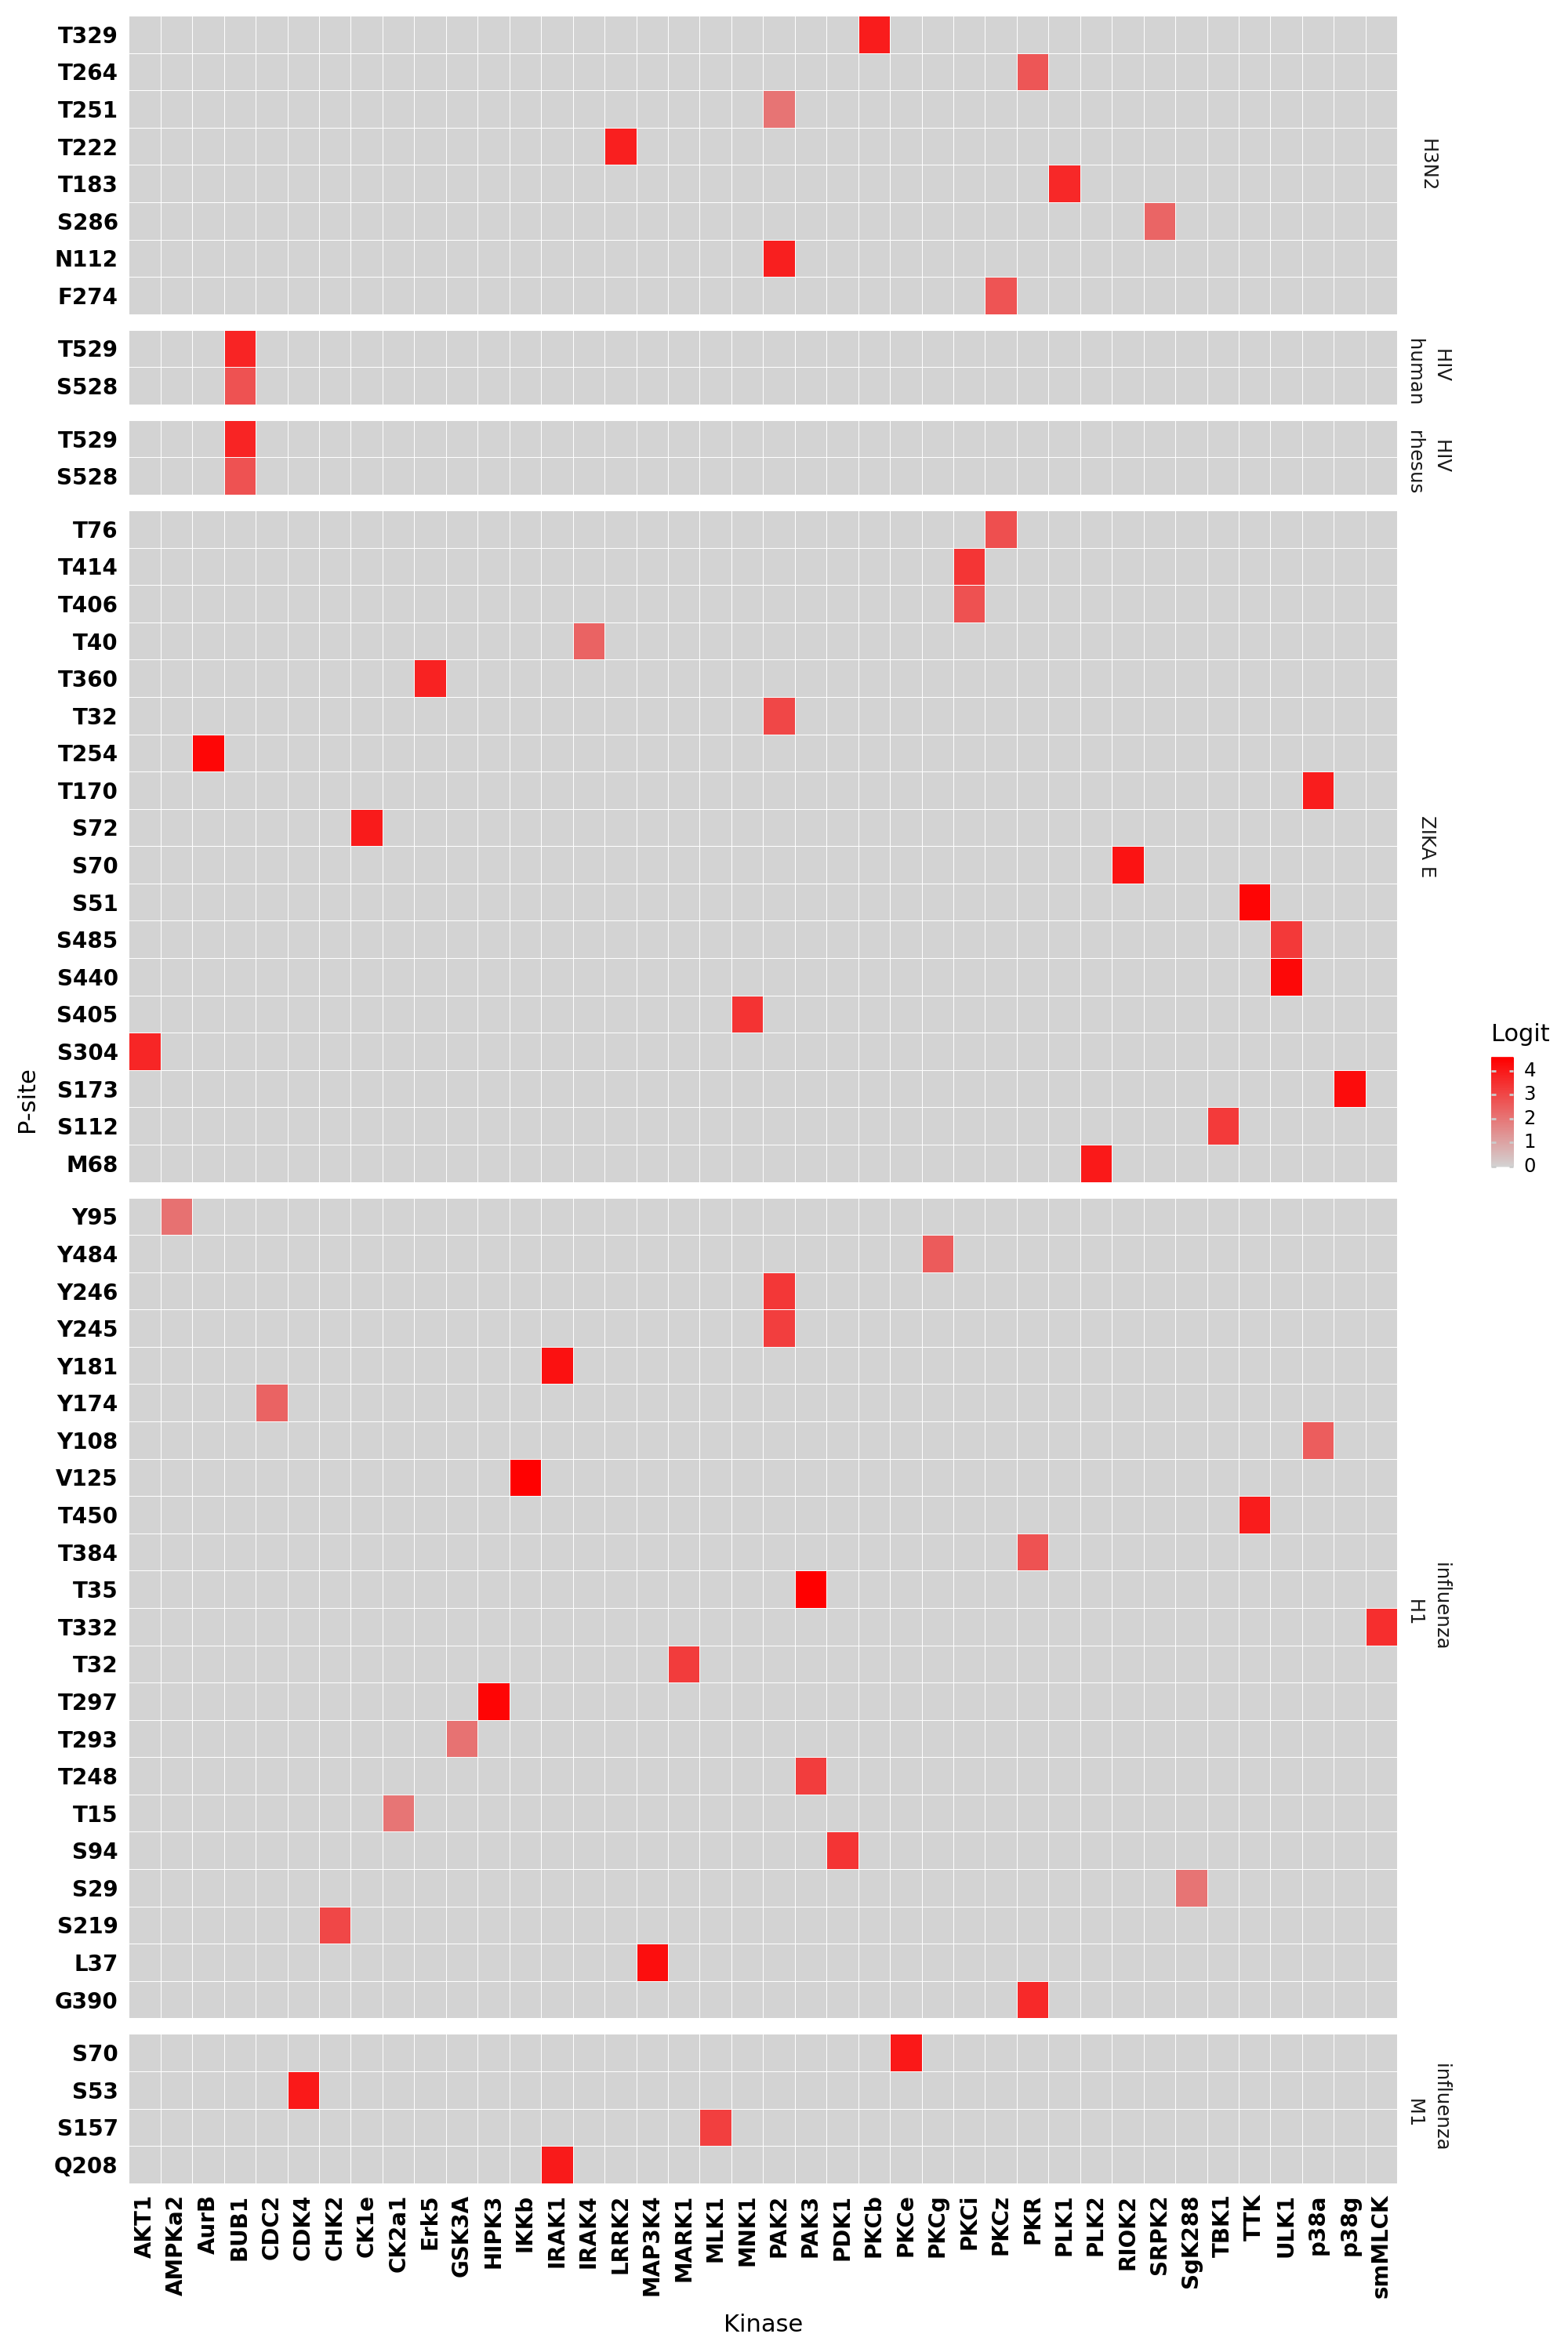

In [695]:

p1

In [696]:
drug_long.loc[(drug_long['kinase']=='BUB1')&(drug_long['hit']=='1'),:]

,drug,kinase,hit,drug_lbl
853,BAY 1816032,BUB1,1,BAY 181603...


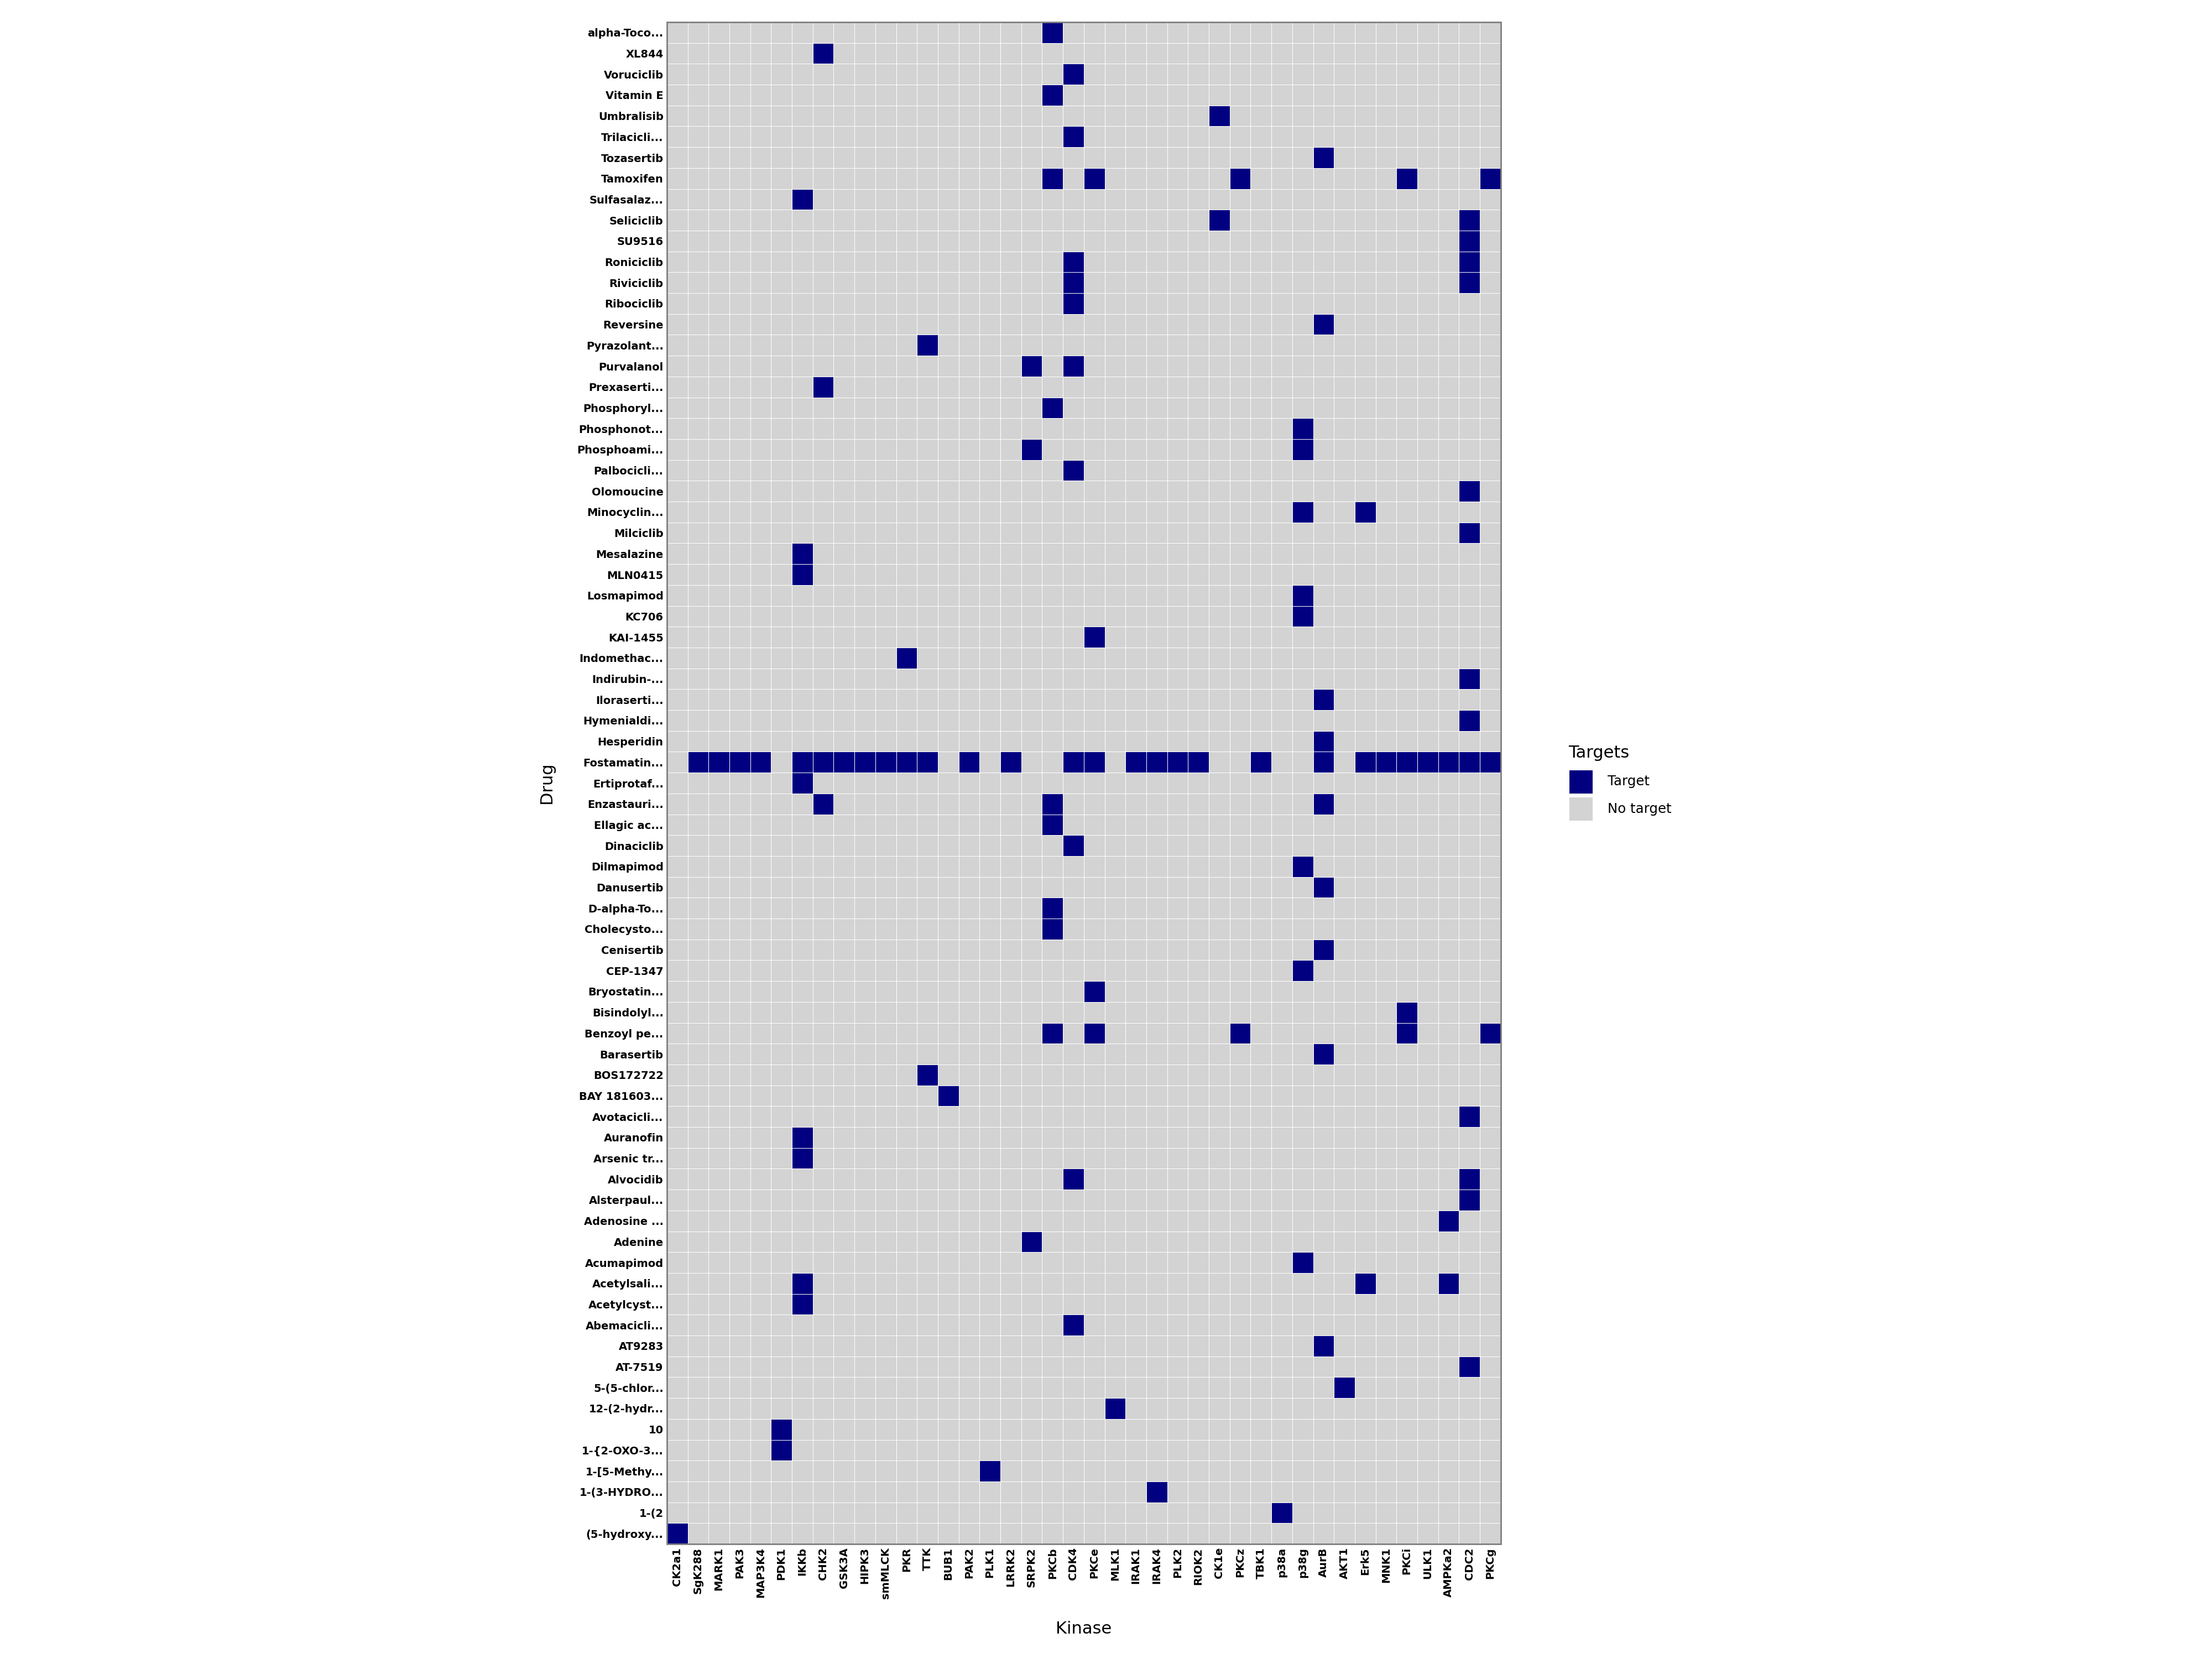

In [698]:

import pandas as pd

def build_drug_kinase_binary_filled(filtered_df):
    df = filtered_df.copy()

    # local kinase order (only from data)
    kinase_order = (
        df["top_kinase"]
        .dropna()
        .astype(str)
        .unique()
        .tolist()
    )

    rows = []
    for _, r in df.iterrows():
        # top_drug like "KIN:DrugA;DrugB"
        for kin, drug in parse_passing_drugs(r["top_drug"]):
            rows.append({
                "kinase": str(kin),
                "drug": str(drug),
                "hit": 1
            })

    long = pd.DataFrame(rows)
    if long.empty:
        return long

    # ensure uniqueness + deterministic hit
    long = (
        long
        .groupby(["drug", "kinase"], as_index=False)["hit"]
        .max()
    )

    # ---- Complete the drug × kinase grid ----
    drugs = pd.DataFrame({"drug": long["drug"].unique()})
    kins  = pd.DataFrame({"kinase": kinase_order})

    drugs["key"] = 1
    kins["key"] = 1

    full = (
        drugs.merge(kins, on="key")
             .drop(columns="key")
    )

    out = full.merge(long, on=["drug", "kinase"], how="left")
    out["hit"] = out["hit"].fillna(0).astype(int)

    # lock kinase axis ordering
    out["kinase"] = pd.Categorical(
        out["kinase"],
        categories=kinase_order,
        ordered=True
    )

    return out

drug_long = build_drug_kinase_binary_filled(top_df)

# truncate drug labels AFTER building the grid (so truncation doesn’t collapse distinct drugs)
drug_long["drug_lbl"] = drug_long["drug"].apply(lambda s: s[:10] + "..." if len(s) > 10 else s)

# for manual fill scale
drug_long["hit"] = drug_long["hit"].astype(str)   # "0"/"1"

from plotnine import *


p2 = (
    ggplot(drug_long, aes("kinase", "drug_lbl", fill="hit"))
    + geom_tile(color='white', size=0.2)
    + scale_x_discrete(drop=True, expand=(0, 0))
    + scale_y_discrete(expand=(0, 0))
    + scale_fill_manual(
        values={"0": "lightgray", "1": "navy"},
        breaks=["1", "0"],
        labels=["Target", "No target"]
    )
    + labs(x="Kinase", y="Drug", fill="Targets")
    + theme_bw()
    + theme(
        panel_background=element_rect(fill="white"),
        axis_text_x=element_text(size=7, color="black", weight="bold", rotation=90),
        axis_text_y=element_text(size=7, color="black", weight="bold"),
        legend_position="right",
        figure_size=(20, 15),
        axis_ticks_length=0,
        panel_spacing=0.15,
    )
    + coord_fixed(ratio=1)
)

p2.show()




In [668]:
import pandas as pd

def parse_drug_list_from_top_drug(top_drug):
    """
    top_drug: string like "KIN:DrugA;DrugB" or None
    returns ["DrugA","DrugB"]
    """
    if top_drug is None or (isinstance(top_drug, float) and pd.isna(top_drug)):
        return []
    s = str(top_drug)
    if ":" not in s:
        return []
    rhs = s.split(":", 1)[1].strip()
    if not rhs:
        return []
    return [d.strip() for d in rhs.split(";") if d.strip()]

def build_logit_long_by_drug(filtered_df):
    df = filtered_df.copy()
    df["psite"] = make_psite_label(df)

    rows = []
    for _, r in df.iterrows():
        logit_map = parse_prob_list(r["pred_kinase_prob"])  # kinase -> logit

        # top kinase is a scalar string in your top_df
        kin = str(r["top_kinase"]) if pd.notna(r["top_kinase"]) else None
        if not kin or kin not in logit_map:
            continue

        logit_val = logit_map[kin]

        # explode drugs for this top kinase
        for drug in parse_drug_list_from_top_drug(r["top_drug"]):
            rows.append({
                "substrate": r["substrate"],
                "psite": r["psite"],
                "drug": drug,
                "logit": logit_val
            })

    long = pd.DataFrame(rows)
    if long.empty:
        return long

    # if duplicates happen, keep max logit (safe)
    long = long.groupby(["substrate", "psite", "drug"], as_index=False)["logit"].max()
    return long

logit_drug_long = build_logit_long_by_drug(top_df)

def complete_with_zeros_drug(df):
    df = df.copy()

    drug_order = (
        df["drug"].dropna().astype(str).unique().tolist()
    )

    idx = (
        df[["substrate", "psite"]]
        .drop_duplicates()
        .assign(key=1)
        .merge(pd.DataFrame({"drug": drug_order, "key": 1}), on="key", how="outer")
        .drop(columns="key")
    )

    out = idx.merge(df, on=["substrate", "psite", "drug"], how="left")
    out["logit"] = out["logit"].fillna(0)

    # lock x ordering inside the plot (optional but nice)
    out["drug"] = pd.Categorical(out["drug"], categories=drug_order, ordered=True)
    return out, drug_order

logit_drug_filled, DRUG_ORDER = complete_with_zeros_drug(logit_drug_long)
from plotnine import *
def shorten_drug_label(s, max_len=12):
    s = str(s)
    return s if len(s) <= max_len else s[:max_len] + "…"

p_drug = (
    ggplot(logit_drug_filled, aes("drug", "psite", fill="logit"))
    + geom_tile(color="gray", size=0.2)
    + scale_x_discrete(
        expand=(0, 0),
        drop=False,
        labels=lambda labs: [shorten_drug_label(x, 12) for x in labs]
    )
    + scale_y_discrete(expand=(0, 0))
    + facet_grid("substrate ~ .", scales="free_y", space="free_y")
    + coord_cartesian(expand=False)
    + labs(x="Drug", y="P-site", fill="Logit")
    + theme_minimal()
   + theme(
        panel_background=element_rect(fill="white"),
        axis_text_x=element_text(size=7, color="black", weight="bold", rotation=90),
        axis_text_y=element_text(size=7, color="black", weight="bold"),
        legend_position="right",
        figure_size=(20, 15),
    )
)


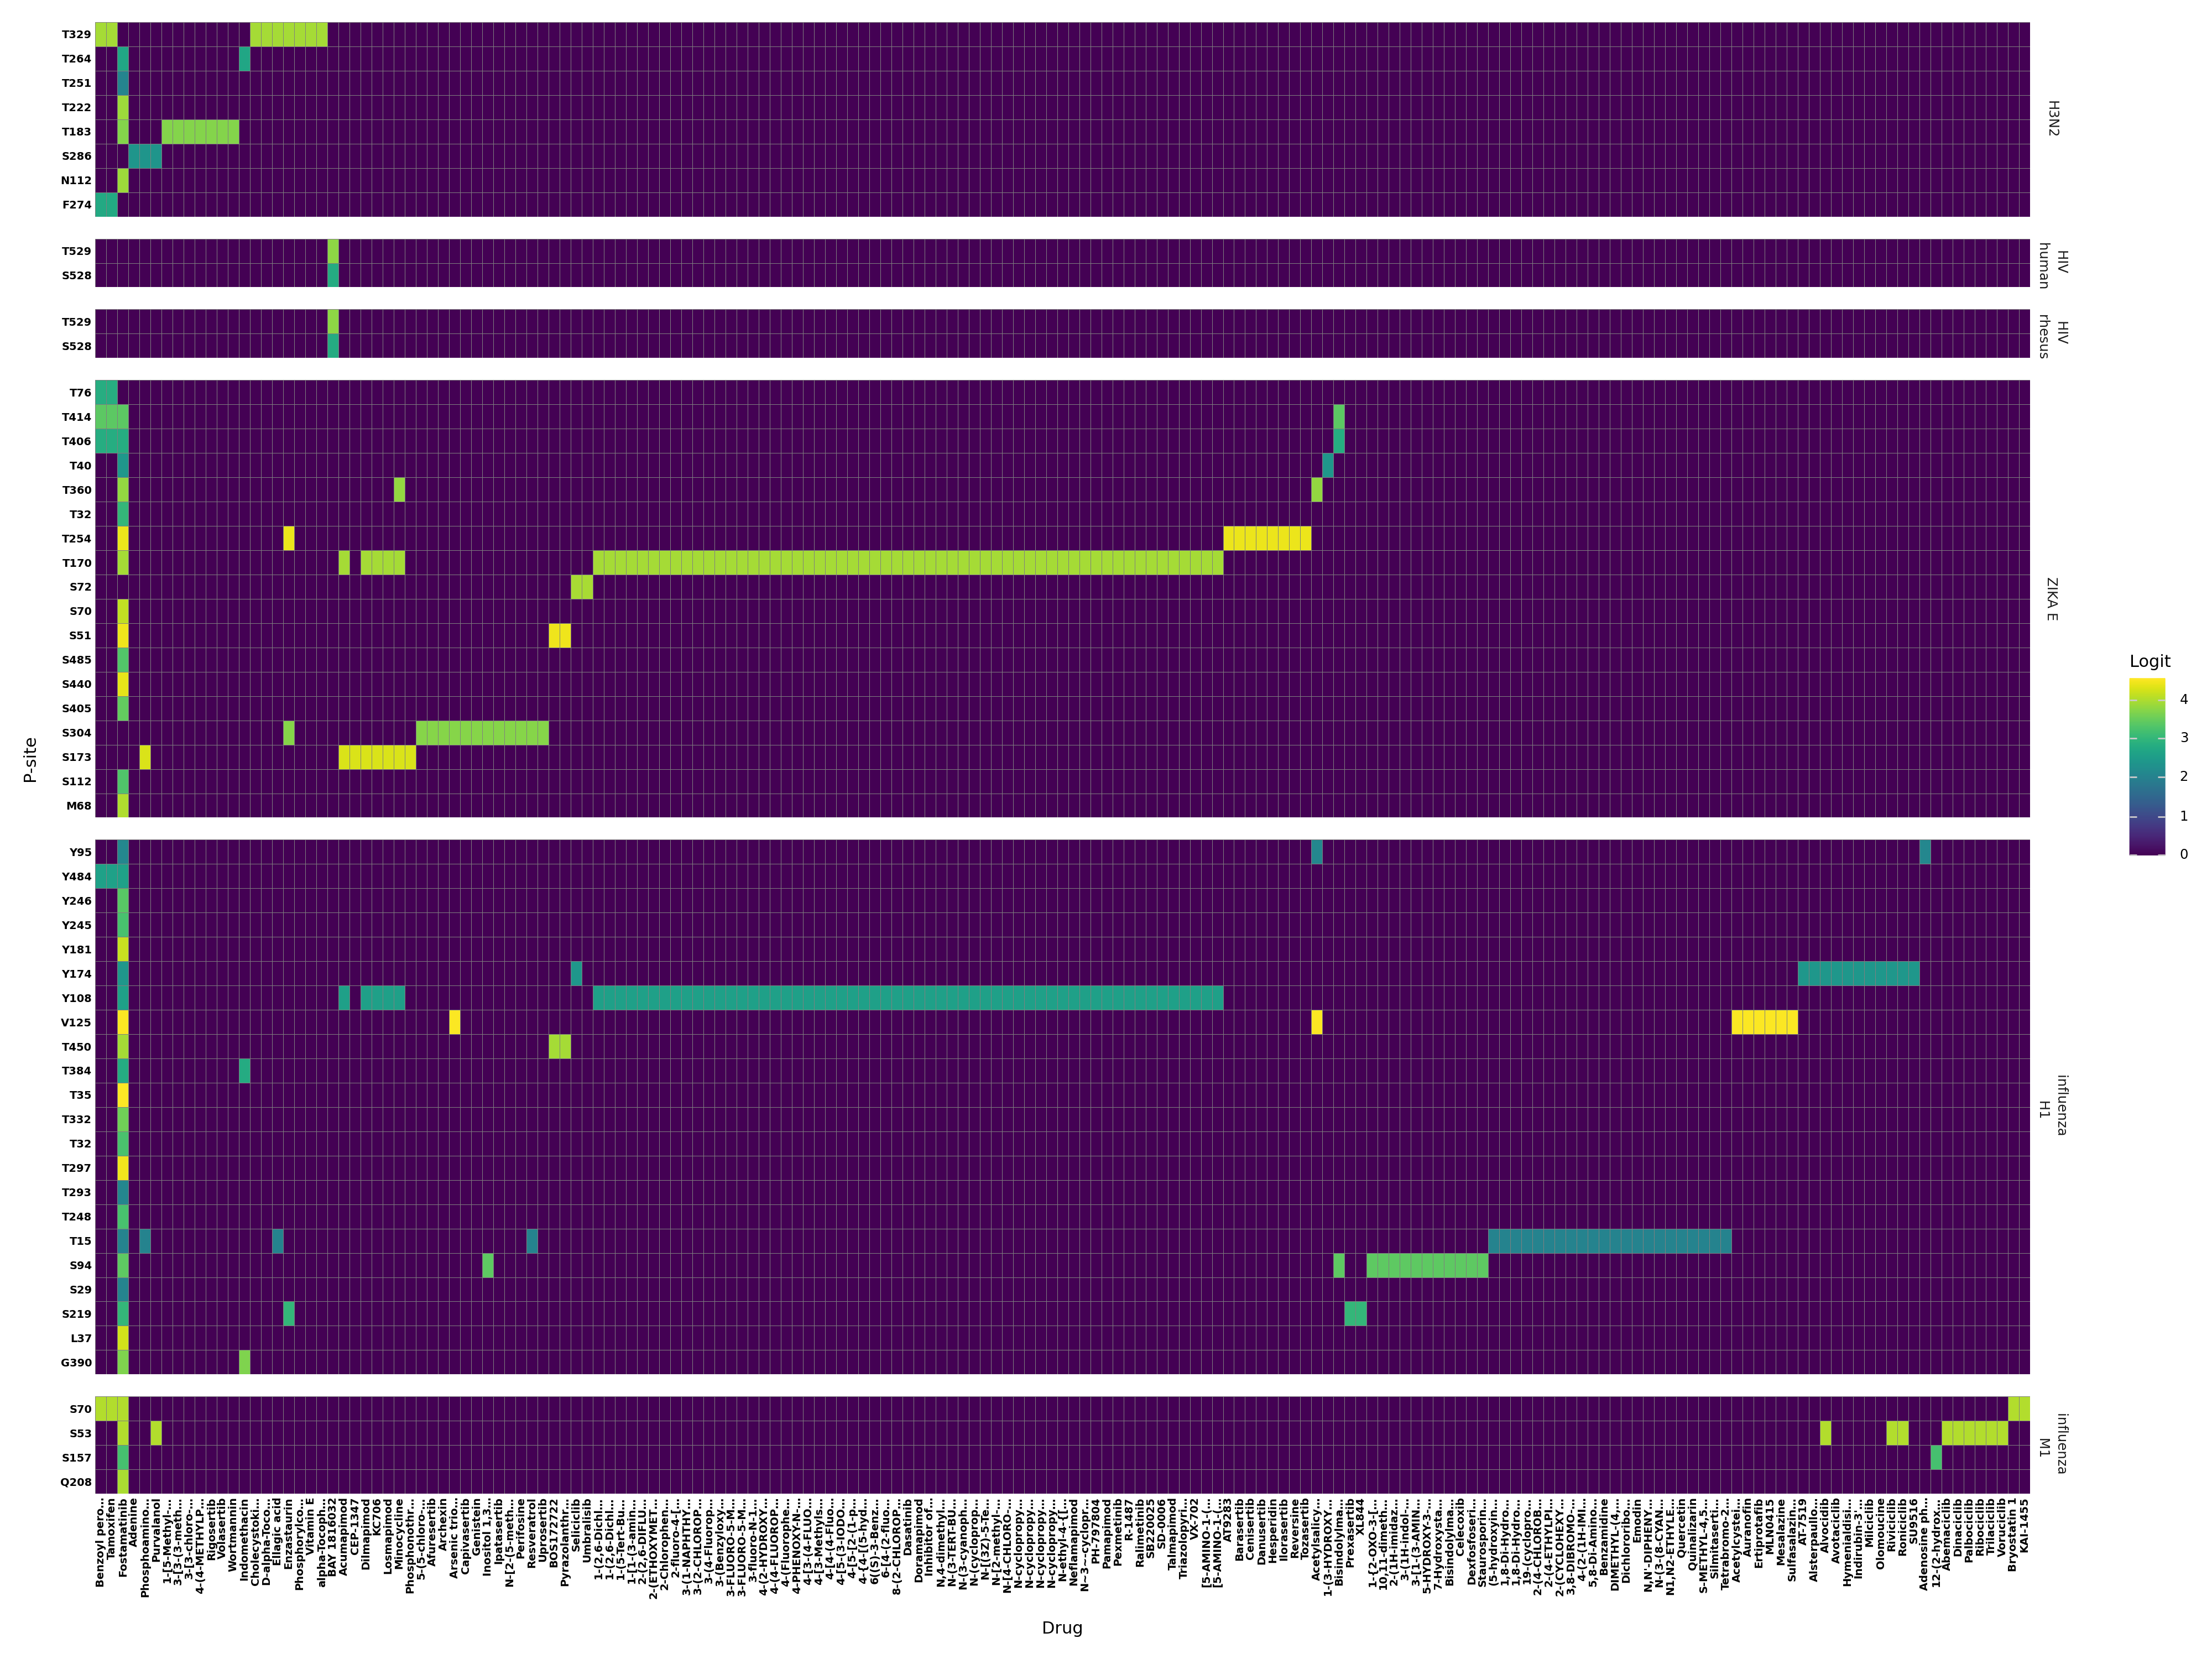

In [669]:
p_drug.show()

In [145]:
dms_candidates_inference_kinbertv1.to_csv("../../data/virus_dms/dms_candidates_inference_kinbertv1.csv")

In [32]:
dms_candidates_inference_kinbertv1 = pd.read_csv("../../data/virus_dms/dms_candidates_inference_kinbertv1.csv")

In [34]:
dms_candidates_inference_kinbertv1.loc[dms_candidates_inference_kinbertv1["substrate"]=="ZIKA_E",:]["matched_drug"].iloc[1]

"['TTBK1:', 'TBK1:Fostamatinib', 'CK1d:', 'TTBK2:', 'CK1e:Seliciclib;Umbralisib', 'ADCK5:', 'RIOK3:Fostamatinib', 'Wee1B:', 'TTK:Pyrazolanthrone;Fostamatinib;BOS172722', 'CaMK1b:']"

In [8]:
pd.read_pickle("../../data/virus_dms/dms_candidate_psites.pkl")["substrate_seq"].iloc[-1]

'IRCIGVSNRDFVEGMSGGTWVDVVLEHGGCVTVMAQDKPTVDIELVTTTVSNMAEVRSYCYEASISDMASDSRCPTQGEAYLDKQSDTQYVCKRTLVDRGWGNGCGLFGKGSLVTCAKFTCSKKMTGKSIQPENLEYRIMLSVHGSQHSGMIVNDTGYETDENRAKVEVTPNSPRAEATLGGFGSLGLDCEPRTGLDFSDLYYLTMNNKHWLVHKEWFHDIPLPWHAGADTGTPHWNNKEALVEFKDAHAKRQTVVVLGSQEGAVHTALAGALEAEMDGAKGKLFSGHLKCRLKMDKLRLKGVSYSLCTAAFTFTKVPAETLHGTVTVEVQYAGTDGPCKIPVQMAVDMQTLTPVGRLITANPVITESTENSKMMLELDPPFGDSYIVIGVGDKKITHHWHRSGSTIGKAFEATVRGAKRMAVLGDTAWDFGSVGGVFNSLGKGIHQIFGAAFKSLFGGMSWFSQILIGTLLVWLGLNTKNGSISLTCLALGGVMIFLSTAVSA'

In [27]:
zika_e = "IRCIGVSNRDFVEGMSGGTWVDVVLEHGGCVTVMAQDKPTVDIELVTTTVSNMAEVRSYCYEASISDMASDSRCPTQGEAYLDKQSDTQYVCKRTLVDRGWGNGCGLFGKGSLVTCAKFTCSKKMTGKSIQPENLEYRIMLSVHGSQHSGMIVNDTGYETDENRAKVEVTPNSPRAEATLGGFGSLGLDCEPRTGLDFSDLYYLTMNNKHWLVHKEWFHDIPLPWHAGADTGTPHWNNKEALVEFKDAHAKRQTVVVLGSQEGAVHTALAGALEAEMDGAKGKLFSGHLKCRLKMDKLRLKGVSYSLCTAAFTFTKVPAETLHGTVTVEVQYAGTDGPCKIPVQMAVDMQTLTPVGRLITANPVITESTENSKMMLELDPPFGDSYIVIGVGDKKITHHWHRSGSTIGKAFEATVRGAKRMAVLGDTAWDFGSVGGVFNSLGKGIHQIFGAAFKSLFGGMSWFSQILIGTLLVWLGLNTKNGSISLTCLALGGVMIFLSTAVSA"
zika_e[69-7:69+8]

'ASISDMASDSRCPTQ'

## For now, stick to kinbertv1 predictions since it's more reasonable and potentially less biased from the hela lysate dataset

In [136]:
dms_candidates_inference_kinbertv1_summed = dms_candidates_inference_kinbertv1.groupby("substrate").agg({"pred_kinase": 'sum'}).reset_index()

In [140]:
dms_candidates_inference_kinbertv1_summed["pred_kinase"] = dms_candidates_inference_kinbertv1_summed["pred_kinase"].apply(lambda s: list(set(s)))

In [141]:
dms_candidates_inference_kinbertv1_summed["matched_drug"] = dms_candidates_inference_kinbertv1_summed["pred_kinase"].apply(lambda s: [fetch_drug(kin) for kin in s])

In [143]:
dms_candidates_inference_kinbertv1_summed.to_csv("../../data/virus_dms/dms_candidates_inference_kinbertv1_summed.csv")